# 0. SETUP & DATA LOADING

In [1]:
#import lib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import os
import gc

In [ ]:
# Setup dynamic paths for Kaggle and Local environments
file_path = '/kaggle/input/datasets/pgnjams/narrativecastdataset-ie403/reddit_technology_madoc-001.parquet'
local_full_path = '../data/raw/reddit_technology_madoc-001.parquet'
local_sample_path = '../data/samples/posts_sample.csv'

if os.path.exists('/kaggle/input'):
    data_path = file_path
    output_dir = '/kaggle/working/'
    print("Running on Kaggle. Loading full dataset...")
elif os.path.exists(local_full_path):
    data_path = local_full_path
    output_dir = '../outputs/data_profiling/'
    print("Running on Local. Loading full dataset...")
else:
    data_path = local_sample_path
    output_dir = '../outputs/data_profiling/'
    print("Running on Local. Loading sample dataset...")

os.makedirs(output_dir, exist_ok=True)

try:
    df = pd.read_parquet(data_path) if data_path.endswith('.parquet') else pd.read_csv(data_path)
    print("Data loaded successfully.")
except Exception as e:
    print(f"Error loading data: {e}")

Running on Local. Loading full dataset...
Data loaded successfully.


In [3]:
#Read dataset and preview
df.head(10)

,post_id,publish_date,user_id,parent_id,parent_user_id,content,url,language,interaction_type,platform,community,strict_filter,sentiment_vader
0,a2e5ce4e-6364-5e81-8e29-2798b8ed0ac8,1388534416,4023b3e6-8843-51eb-89ad-e6fffc648b41,None,None,"Leica, voigtlander, Fuji, and the like will su...",None,English,COMMENT,reddit,technology,None,0.8934
1,05da00c8-5bf5-5630-a68e-9065e633f7c9,1388534428,cb330a80-fc1b-54a7-b627-763f33dc9fc0,None,None,Hi everyone! I literally have no idea what is ...,None,English,COMMENT,reddit,technology,None,0.9059
2,3d0f898a-a643-5871-aefd-d7cb3684dbf6,1388534439,dfb76de3-51f5-57bc-a1e4-2663d72b5c9a,None,None,Tri-corder,None,English,COMMENT,reddit,technology,None,0.0000
3,0794186e-4a21-5f75-8fdd-52874f2fc50b,1388534460,579a1ae7-b39f-56fe-877e-b3bf95824932,None,None,Enhanced network security controls: the real v...,http://www.connectikpeople.co/2013/12/enhanced...,English,POST,reddit,technology,None,0.5859
4,45b4c2ac-2e4d-5d59-beba-ec071a1ee46d,1388534474,1f29b11b-b371-580e-9168-f4f19a552820,None,None,I know. They were being dicks about it. I don'...,None,English,COMMENT,reddit,technology,None,-0.8890
5,866e2205-b1fb-57d4-a7d2-0074473e454c,1388534494,fb1b7d32-72b5-50ed-8912-7ca38d40492e,None,None,"Thanks for this, I truly had no idea what was ...",None,English,COMMENT,reddit,technology,None,0.5574
6,6350b768-83b0-5185-bec2-f1f3e10bc3d8,1388534551,355a3a86-423b-5994-a63d-bf63d448ce2c,None,None,The xeon in the $2999 mac pro is a xeon e5 162...,None,English,COMMENT,reddit,technology,None,0.0000
7,4f6086f2-8647-501f-bcb5-fed71dd9d56f,1388534580,e9d8c038-5ded-5ff8-bd89-0c8b9241447d,None,None,"Thanks a bunch, great ELI5",None,English,COMMENT,reddit,technology,None,0.7906
8,2150b5a8-2fce-5e04-a22a-782da5218956,1388534621,c81635cd-5f72-581a-808e-d066aea8afb9,None,None,10 Real Tech to watch in 2014,http://www.investorsbeat.com/10-real-tech-to-w...,English,POST,reddit,technology,None,0.0000
9,30acc1d6-2c04-5a21-b2ef-58b90ab6f31b,1388534623,c7e17b64-b4f3-5f5e-96a2-b51718a9e3b8,None,None,Male Edge Usa,http://www.youtube.com/watch?v=xT6ncO35YVA,English,POST,reddit,technology,None,0.0000


# 1. DATA OVERVIEW & STRUCTURE


In [4]:
#Check shape,data types, missing values, and duplicates
print("Dataset Shape:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (11766134, 13)

Data Types:
 post_id                     object
publish_date                 int64
user_id                     object
parent_id                   object
parent_user_id              object
content             string[python]
url                         object
language            string[python]
interaction_type    string[python]
platform                    object
community                   object
strict_filter               object
sentiment_vader            float64
dtype: object

Missing Values:
 post_id                    0
publish_date               0
user_id                    0
parent_id            9693194
parent_user_id       9686745
content                    0
url                 10338180
language                   0
interaction_type           0
platform                   0
community                  0
strict_filter       11766134
sentiment_vader            0
dtype: int64

Duplicate Rows: 0


In [5]:
# Calculate missing value percentages
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Percentage (%)': missing_pct})

print("MISSING VALUES PERCENTAGE:\n")
print(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Percentage (%)', ascending=False))
print("\n")

MISSING VALUES PERCENTAGE:

                Missing Count  Percentage (%)
strict_filter        11766134      100.000000
url                  10338180       87.863864
parent_id             9693194       82.382149
parent_user_id        9686745       82.327339




# 2. CATEGORICAL PROFILING
Thống kê các trường phân loại để đánh giá mức độ đa dạng của nền tảng, ngôn ngữ và loại hình tương tác.

In [6]:
print("CATEGORICAL FEATURES VALUE COUNTS\n")

cat_cols = ['interaction_type', 'platform', 'language', 'community']

for col in cat_cols:
    if col in df.columns:
        print(df[col].value_counts(dropna=False).head(10))
        print(f"Unique values: {df[col].nunique()}\n")

CATEGORICAL FEATURES VALUE COUNTS

interaction_type
COMMENT    10918477
POST         847657
Name: count, dtype: Int64
Unique values: 2

platform
reddit    11766134
Name: count, dtype: int64
Unique values: 1

language
English    11766134
Name: count, dtype: Int64
Unique values: 1

community
technology    11766134
Name: count, dtype: int64
Unique values: 1



# 3. NUMERIC & TEXT LENGTH
Phân tích phân bố độ dài văn bản (word_count) và cảm xúc (sentiment). Đánh giá tỷ lệ văn bản quá ngắn (< 3 hoặc 5 từ) để chuẩn bị cho bước Text Embedding.

In [7]:
# Calculate word count
df['word_count'] = df['content'].str.count(' ').fillna(0) + 1
df['word_count'] = df['word_count'].astype('int32')

print("NUMERIC FEATURES DESCRIPTIVE STATISTICS:\n")
numeric_cols = ['sentiment_vader', 'word_count']
desc_stats = df[numeric_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.99]).T

print(desc_stats)

NUMERIC FEATURES DESCRIPTIVE STATISTICS:

                      count       mean        std  min     25%   50%      75%  \
sentiment_vader  11766134.0   0.054505   0.486806 -1.0  -0.296   0.0   0.4404   
word_count       11766134.0  37.090913  54.512322  1.0  10.000  20.0  43.0000   

                     90%       99%     max  
sentiment_vader   0.7269    0.9538     1.0  
word_count       83.0000  251.0000  6741.0  


In [8]:
# Evaluate the proportion of extremely short texts
short_text_threshold_1 = 3
short_text_threshold_2 = 5

short_texts_3 = (df['word_count'] < short_text_threshold_1).sum()
short_texts_5 = (df['word_count'] < short_text_threshold_2).sum()

print("SEMANTIC VIABILITY (SHORT TEXTS):\n")
print(f"Texts with < {short_text_threshold_1} words: {short_texts_3} ({(short_texts_3/len(df))*100:.2f}%)")
print(f"Texts with < {short_text_threshold_2} words: {short_texts_5} ({(short_texts_5/len(df))*100:.2f}%)")

SEMANTIC VIABILITY (SHORT TEXTS):

Texts with < 3 words: 273960 (2.33%)
Texts with < 5 words: 833003 (7.08%)


# 4. TEMPORAL DISTRIBUTION & DENSITY
Xác định khung thời gian, đo lường lưu lượng theo năm và tính toán mật độ bài viết trung bình theo ngày/tuần để thiết lập Time Horizon.

In [9]:

print("TEMPORAL DISTRIBUTION:\n")

# Convert UNIX timestamp
df['publish_date'] = pd.to_datetime(df['publish_date'], unit='s', errors='coerce')

print("Timeline Range:")
print(f"From: {df['publish_date'].min()}")
print(f"To:   {df['publish_date'].max()}\n")

# Aggregate counts by year
print("---Yearly Volume---")
df['publish_year'] = df['publish_date'].dt.year
yearly_volume = df['publish_year'].value_counts().sort_index()
print("Yearly Volume:\n", yearly_volume, "\n")

# Aggregate counts by month
print("---Monthly Volume---")
df['year_month'] = df['publish_date'].dt.to_period('M')
monthly_volume = df['year_month'].value_counts().sort_index()
print(monthly_volume)

# Cleanup
df = df.drop(columns=['publish_year', 'year_month'])
gc.collect()

TEMPORAL DISTRIBUTION:

Timeline Range:
From: 2014-01-01 00:00:16
To:   2020-12-31 23:59:25

---Yearly Volume---
Yearly Volume:
 publish_year
2014    1885978
2015    1775925
2016    1786531
2017    1690399
2018    1614498
2019    1445479
2020    1567324
Name: count, dtype: int64 

---Monthly Volume---
year_month
2014-01    212083
2014-02    187787
2014-03    213964
2014-04    175018
2014-05    132666
            ...  
2020-08    148198
2020-09    121354
2020-10    136207
2020-11    138216
2020-12    150248
Freq: M, Name: count, Length: 84, dtype: int64


58

In [10]:
# Calculate daily and weekly interaction volume stats
daily_volume = df['publish_date'].dt.floor('D').value_counts()
weekly_volume = df['publish_date'].dt.to_period('W').value_counts()

print("TEMPORAL DENSITY METRICS:\n")
print("Daily Volume Stats:")
print(daily_volume.describe().apply(lambda x: format(x, '.2f')))
print("\nWeekly Volume Stats:")
print(weekly_volume.describe().apply(lambda x: format(x, '.2f')))


TEMPORAL DENSITY METRICS:

Daily Volume Stats:
count     2557.00
mean      4601.54
std       1630.89
min       1372.00
25%       3456.00
50%       4331.00
75%       5428.00
max      17054.00
Name: count, dtype: object

Weekly Volume Stats:
count      366.00
mean     32147.91
std       6257.69
min      19357.00
25%      27838.50
50%      31410.50
75%      35382.25
max      60835.00
Name: count, dtype: object


# 5. VISUALIZATION

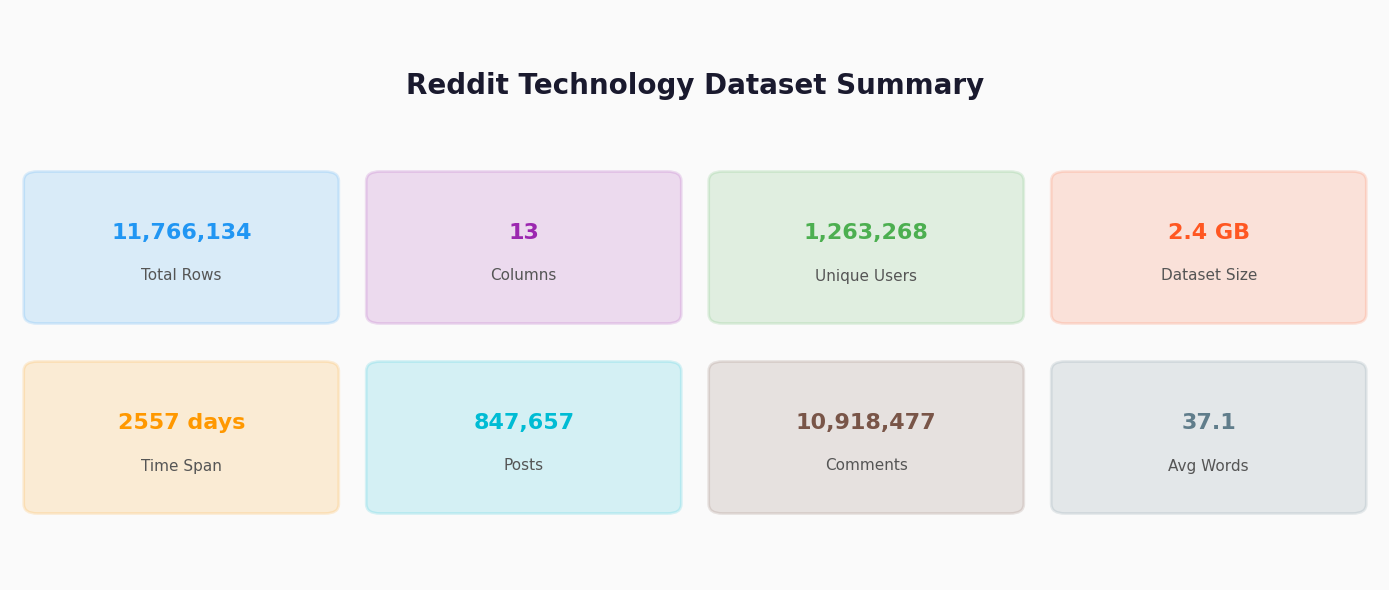

In [11]:
#DATASET SUMMARY CARDS
# Set minimal style
plt.rcParams.update({
    "axes.facecolor": "#fafafa", 
    "figure.facecolor": "#fafafa",
    "axes.titleweight": "bold"
})

fig, ax = plt.subplots(figsize=(14, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

ax.text(5, 5.2, "Reddit Technology Dataset Summary", ha="center", va="center", fontsize=20, color="#1a1a2e", fontweight="bold")

# Calculate metrics safely
total_rows = len(df)
eda_generated_cols = ['word_count', 'publish_year', 'year_month', 'datetime', 'dt']
added_cols_count = len([col for col in eda_generated_cols if col in df.columns])
total_cols = len(df.columns) - added_cols_count

unique_users = df['user_id'].nunique()

try:
    dataset_size_gb = os.path.getsize(data_path) / (1024 ** 3)
except Exception:
    dataset_size_gb = df.memory_usage(deep=True).sum() / (1024 ** 3)

time_span = (df['publish_date'].max() - df['publish_date'].min()).days + 1
posts_count = (df['interaction_type'] == 'POST').sum()
comments_count = (df['interaction_type'] == 'COMMENT').sum()
avg_words = df['word_count'].mean()

# Card layout
cards = [
    (1.25, 3.5, f"{total_rows:,.0f}", "Total Rows", "#2196F3"),
    (3.75, 3.5, f"{total_cols}", "Columns", "#9C27B0"),
    (6.25, 3.5, f"{unique_users:,.0f}", "Unique Users", "#4CAF50"),
    (8.75, 3.5, f"{dataset_size_gb:.1f} GB", "Dataset Size", "#FF5722"),
    (1.25, 1.5, f"{time_span} days", "Time Span", "#FF9800"),
    (3.75, 1.5, f"{posts_count:,.0f}", "Posts", "#00BCD4"),
    (6.25, 1.5, f"{comments_count:,.0f}", "Comments", "#795548"),
    (8.75, 1.5, f"{avg_words:.1f}", "Avg Words", "#607D8B")
]

# Render cards
for x, y, value, label, color in cards:
    rect = mpatches.FancyBboxPatch((x - 1.05, y - 0.7), 2.1, 1.4, boxstyle="round,pad=0.1", 
                                   facecolor=color, alpha=0.15, edgecolor=color, linewidth=2)
    ax.add_patch(rect)
    ax.text(x, y + 0.15, value, ha="center", va="center", fontsize=16, fontweight="bold", color=color)
    ax.text(x, y - 0.3, label, ha="center", va="center", fontsize=11, color="#555")

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "01_dataset_summary_dashboard.pdf"), format='pdf', bbox_inches='tight')
plt.show()

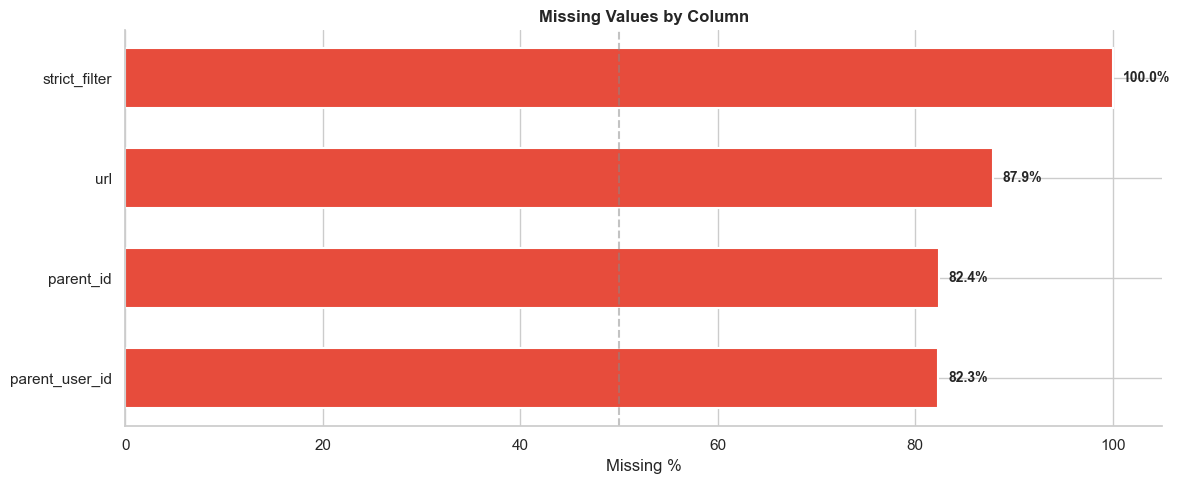

In [12]:
#MISSING VALUES DISTRIBUTION
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 5))

missing_pct = (df.isnull().sum() / len(df)) * 100
missing_pct = missing_pct[missing_pct > 0].sort_values()

colors_miss = ["#e74c3c" if p > 50 else "#2ecc71" for p in missing_pct.values]
bars = ax.barh(missing_pct.index, missing_pct.values, color=colors_miss, height=0.6, edgecolor="white", linewidth=1.5)

ax.set_title("Missing Values by Column")
ax.set_xlabel("Missing %")
ax.axvline(50, color="#888", linestyle="--", alpha=0.5)

for bar, pct in zip(bars, missing_pct.values):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, f"{pct:.1f}%", va="center", fontsize=10, fontweight="bold")

sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "02_missing_values.pdf"), format='pdf', bbox_inches='tight')
plt.show()

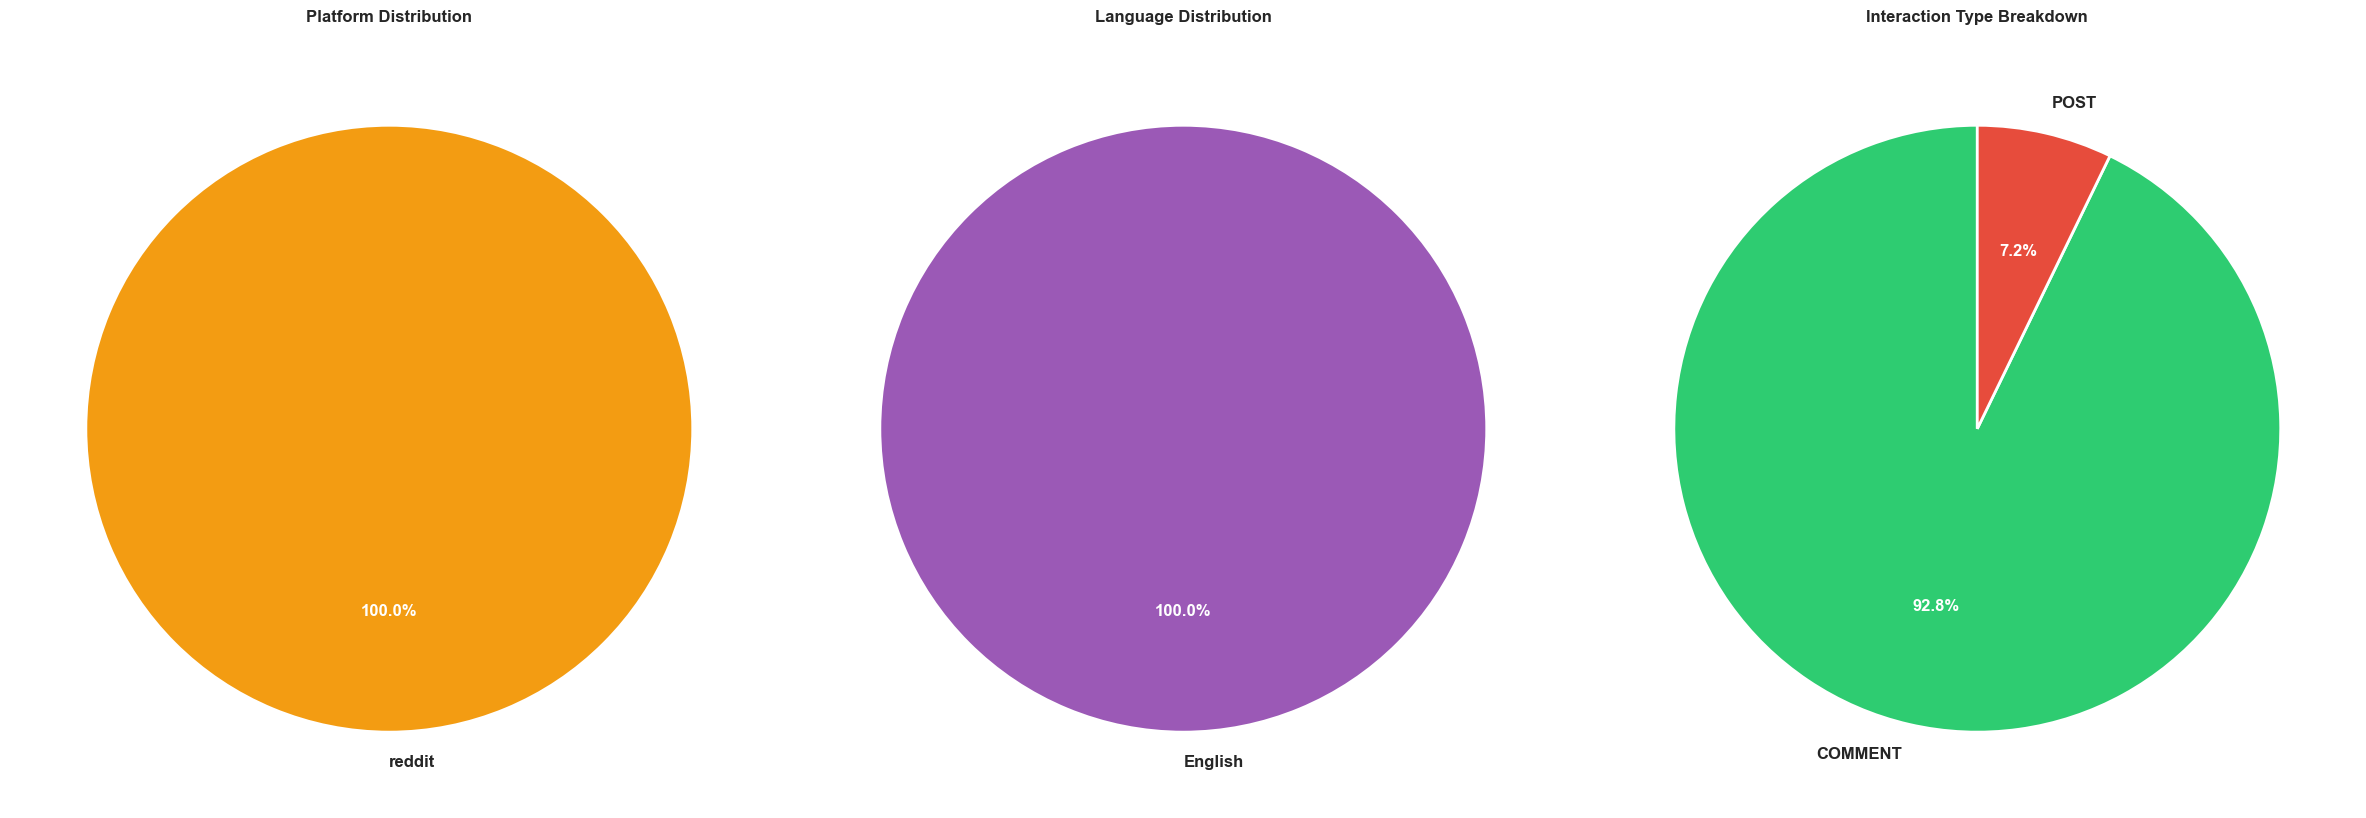

In [14]:
#CATEGORICAL DISTRIBUTIONS
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

chart_configs = [
    {'col': 'platform', 'title': 'Platform Distribution', 'colors': ['#f39c12', '#e67e22', '#d35400']}, 
    {'col': 'language', 'title': 'Language Distribution', 'colors': ['#9b59b6', '#8e44ad', '#2980b9']},
    {'col': 'interaction_type', 'title': 'Interaction Type Breakdown', 'colors': ['#2ecc71', '#e74c3c']}
]

for ax, cfg in zip(axes, chart_configs):
    counts = df[cfg['col']].value_counts()
    
    wedges, texts, autotexts = ax.pie(
        counts, 
        labels=counts.index, 
        autopct='%1.1f%%',
        colors=cfg['colors'], 
        startangle=90, 
        wedgeprops=dict(edgecolor='white', linewidth=2)
    )
    
    plt.setp(autotexts, size=12, weight="bold", color="white")
    plt.setp(texts, size=12, weight="bold")
    ax.set_title(cfg['title'], weight='bold', pad=20)

plt.tight_layout()
plt.savefig(os.path.join(output_dir,"03_categorical_distributions.pdf"),format='pdf',bbox_inches='tight')
plt.show()

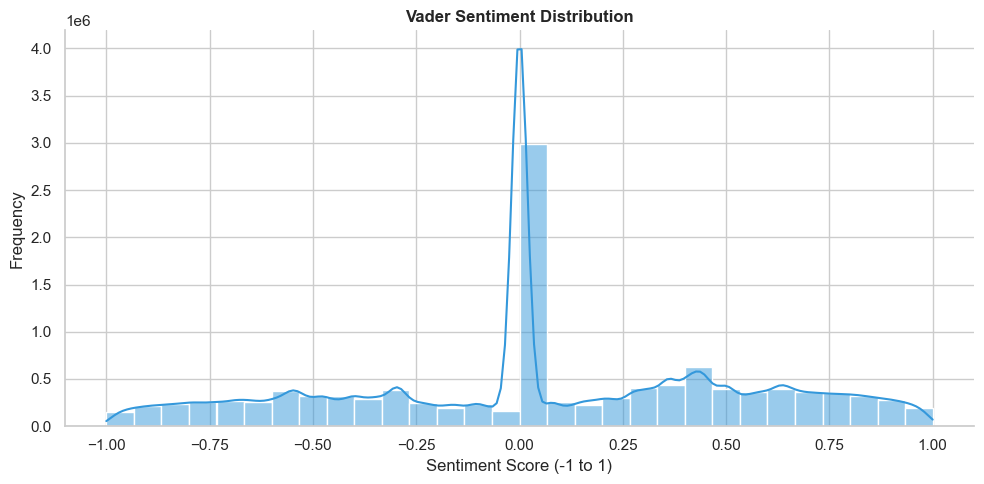

In [15]:
# Plot Vader Sentiment Distribution with KDE curve
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(data=df, x='sentiment_vader', bins=30, color='#3498db', kde=True, ax=ax)
ax.set_title('Vader Sentiment Distribution')
ax.set_xlabel('Sentiment Score (-1 to 1)')
ax.set_ylabel('Frequency')

sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "04_vader_sentiment_distribution.pdf"), format='pdf', bbox_inches='tight')
plt.show()

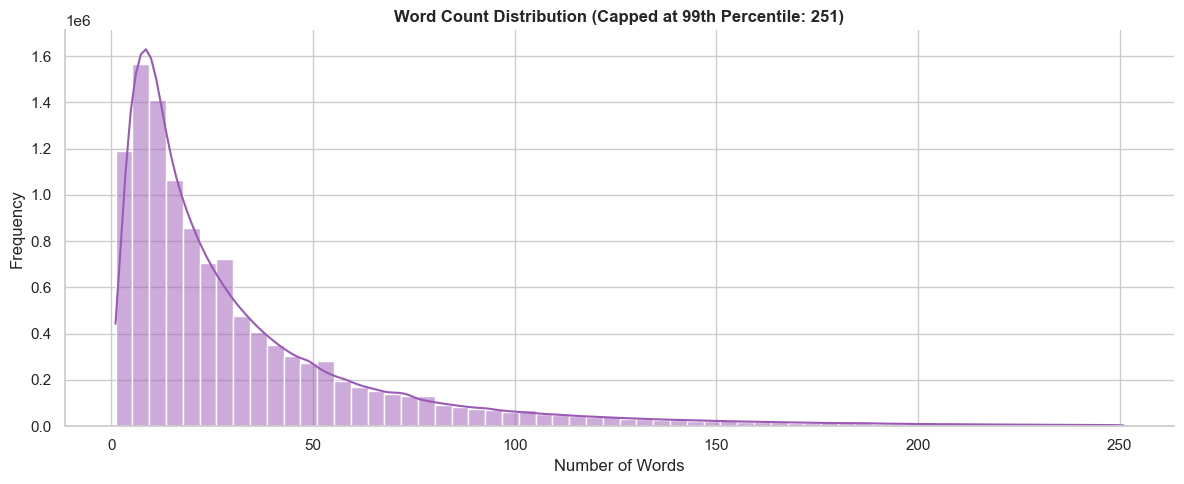

In [16]:
# Plot Word Count Distribution capped at 99th percentile with KDE
fig, ax = plt.subplots(figsize=(12, 5))

p99_word = df['word_count'].quantile(0.99)
plot_data = df[df['word_count'] <= p99_word]

sns.histplot(data=plot_data, x='word_count', bins=60, color='#9b59b6', kde=True, ax=ax)
ax.set_title(f'Word Count Distribution (Capped at 99th Percentile: {p99_word:.0f})')
ax.set_xlabel('Number of Words')
ax.set_ylabel('Frequency')

sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "05_word_count_distribution.pdf"), format='pdf', bbox_inches='tight')
plt.show()

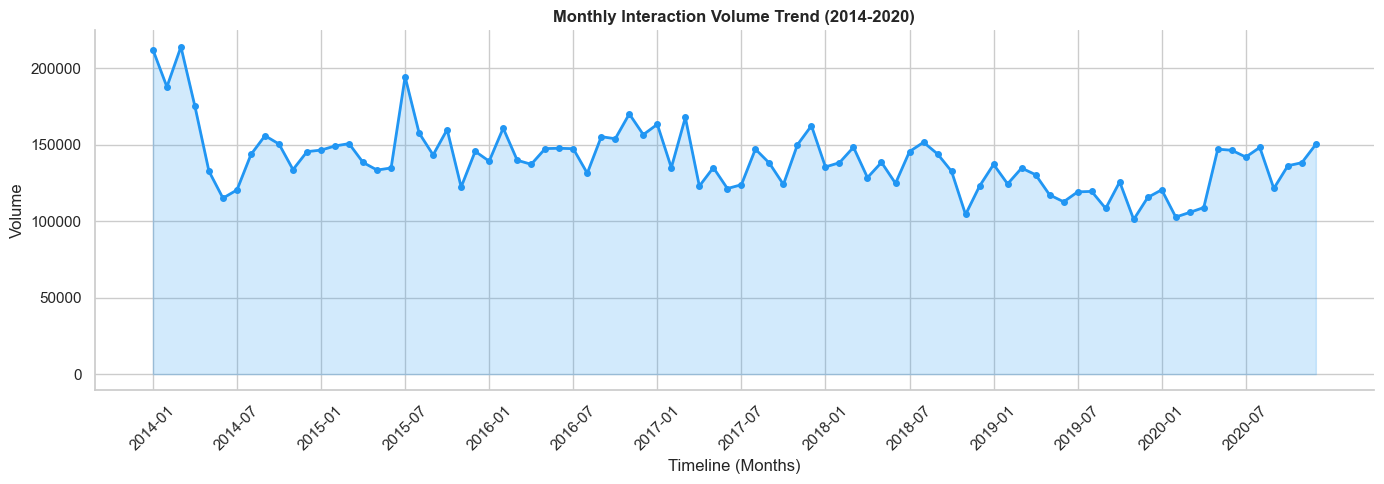

In [17]:
#TEMPORAL TOTAL MONTHLY VOLUME TRENDS
monthly_vol = df['publish_date'].dt.to_period('M').value_counts().sort_index()
monthly_vol.index = monthly_vol.index.astype(str)

fig, ax = plt.subplots(figsize=(14, 5))

ax.fill_between(range(len(monthly_vol)), monthly_vol.values, alpha=0.2, color="#2196F3")
ax.plot(range(len(monthly_vol)), monthly_vol.values, color='#2196F3', linewidth=2, marker='o', markersize=4)

ax.set_title('Monthly Interaction Volume Trend (2014-2020)')
ax.set_xlabel('Timeline (Months)')
ax.set_ylabel('Volume')

plt.xticks(np.arange(0, len(monthly_vol), 6), monthly_vol.index[::6], rotation=45)

sns.despine()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "06_total_monthly_trend.pdf"), format='pdf', bbox_inches='tight')
plt.show()

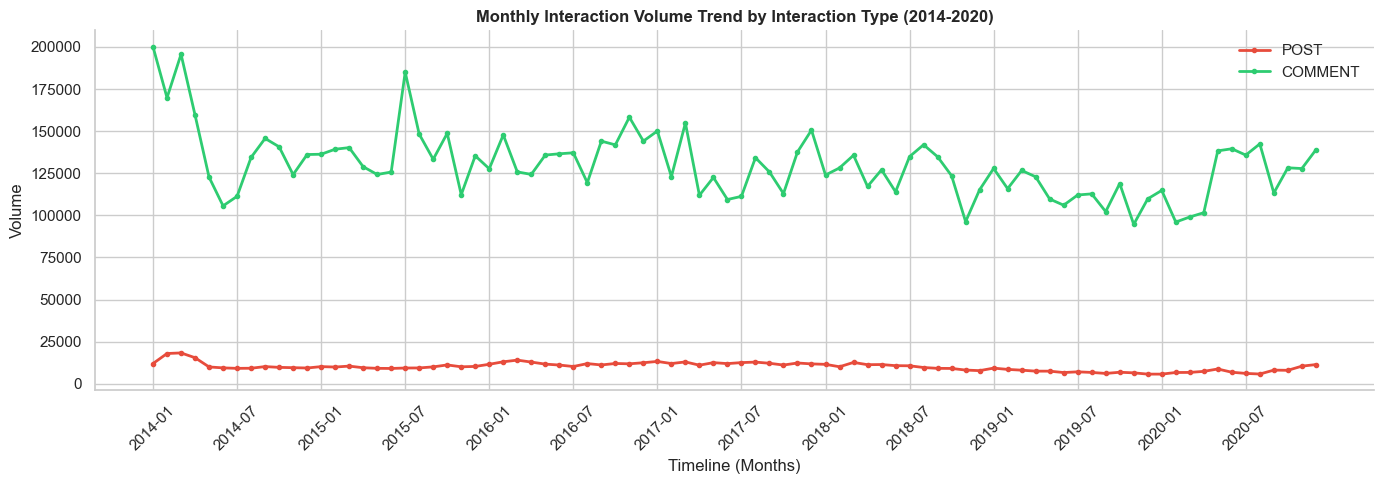

14012

In [18]:
# TEMPORAL VOLUME TREND BY INTERACTION TYPE
df_temp = df[['publish_date', 'interaction_type']].dropna(subset=['publish_date']).copy()
monthly_vol_type = df_temp.groupby([pd.Grouper(key='publish_date', freq='ME'), 'interaction_type']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))

if 'POST' in monthly_vol_type.columns:
    ax.plot(range(len(monthly_vol_type)), monthly_vol_type['POST'], color='#e74c3c', linewidth=2, marker='o', markersize=3, label='POST')
if 'COMMENT' in monthly_vol_type.columns:
    ax.plot(range(len(monthly_vol_type)), monthly_vol_type['COMMENT'], color='#2ecc71', linewidth=2, marker='o', markersize=3, label='COMMENT')

ax.set_title("Monthly Interaction Volume Trend by Interaction Type (2014-2020)", weight='bold')
ax.set_xlabel("Timeline (Months)")
ax.set_ylabel("Volume")
xticks_labels = monthly_vol_type.index.strftime('%Y-%m')
plt.xticks(np.arange(0, len(monthly_vol_type), 6), xticks_labels[::6], rotation=45)

# Clean up visual noise
ax.legend(frameon=False)
sns.despine()

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "07_monthly_trend_by_type.pdf"), format='pdf', bbox_inches='tight')
plt.show()

# Free memory immediately
del df_temp, monthly_vol_type
gc.collect()

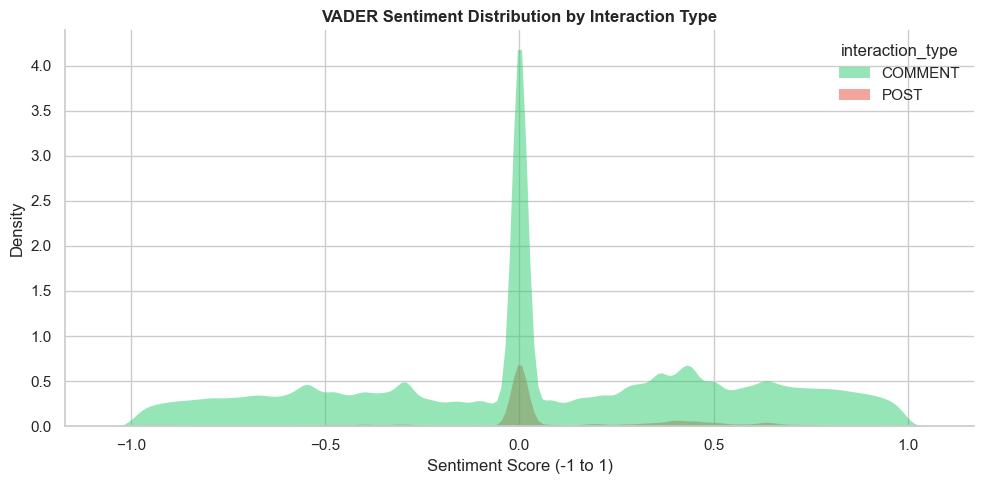

In [19]:
#SENTIMENT BY INTERACTION TYPE
fig, ax = plt.subplots(figsize=(10, 5))

sns.kdeplot(
    data=df, 
    x='sentiment_vader', 
    hue='interaction_type',
    fill=True, 
    alpha=0.5, 
    palette={'POST': '#e74c3c', 'COMMENT': '#2ecc71'}, 
    linewidth=0, 
    ax=ax
)

ax.set_title("VADER Sentiment Distribution by Interaction Type", weight='bold')
ax.set_xlabel("Sentiment Score (-1 to 1)")
ax.set_ylabel("Density")

# Clean up legend and axes
ax.get_legend().set_frame_on(False)
sns.despine()

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "08_sentiment_kde_by_type.pdf"), format='pdf', bbox_inches='tight')
plt.show()